In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/dabhirushirajsinh/submission-ridge-csv/sample.csv
/kaggle/input/competitions/flight-price-prediction/submission.csv
/kaggle/input/competitions/flight-price-prediction/train.csv
/kaggle/input/competitions/flight-price-prediction/test.csv


In [2]:
import os
from pathlib import Path
import warnings
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

In [3]:
input_root = Path("/kaggle/input")
train_candidates = list(input_root.rglob("train.csv"))
test_candidates = list(input_root.rglob("test.csv"))
sample_candidates = list(input_root.rglob("submission.csv"))
if not sample_candidates:
    raise FileNotFoundError("sample_submission.csv not found!")
sample_submission_path = sample_candidates[0]


if not train_candidates or not test_candidates:
    raise FileNotFoundError(
        "Could not find train.csv and test.csv under /kaggle/input. "
        "Use the notebook's Add Input option to attach the flight-price dataset."
    )

# Prefer train/test files from the same directory.
pairs = [(tr, te) for tr in train_candidates for te in test_candidates if tr.parent == te.parent]
if pairs:
    train_path, test_path = pairs[0]
else:
    train_path, test_path = train_candidates[0], test_candidates[0]

print("Training file:", train_path)
print("Test file:", test_path)

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
display(train_df.head())

print("Sample submission file:", sample_submission_path)

sample_submission = pd.read_csv(sample_submission_path)

print("Sample submission shape:", sample_submission.shape)
display(sample_submission.head())
print("Required columns:", sample_submission.columns.tolist())

Training file: /kaggle/input/competitions/flight-price-prediction/train.csv
Test file: /kaggle/input/competitions/flight-price-prediction/test.csv
Train shape: (18076, 12)
Test shape: (4520, 11)


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,2856,Southwest,WN 3596,San Jose,Early_Morning,zero,Morning,Los Angeles,Economy,1.33,5,315
1,21812,Southwest,WN 1307,San Jose,Evening,zero,Evening,San Diego,Economy,1.58,40,149
2,476,United,UA 1763,San Diego,Afternoon,zero,Afternoon,San Francisco,Economy,1.77,2,129
3,21802,Southwest,WN 367,San Jose,Morning,zero,Morning,San Diego,Economy,1.58,40,94
4,5099,United,UA 2117,San Diego,Afternoon,zero,Evening,San Francisco,Economy,1.70,9,146


Sample submission file: /kaggle/input/competitions/flight-price-prediction/submission.csv
Sample submission shape: (4520, 2)


,id,price
0,18395,18395
1,11771,11771
2,22326,22326
3,18332,18332
4,11021,11021


Required columns: ['id', 'price']


In [4]:
# ============================================
# 1. IMPORT LIBRARIES
# ============================================

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [5]:
# ============================================
# 4. FIRST LOOK
# ============================================

print("TRAINING DATA")
display(train_df.head())

print("\nTEST DATA")
display(test_df.head())

print("\nSAMPLE SUBMISSION")
display(sample_submission.head())

TRAINING DATA


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,2856,Southwest,WN 3596,San Jose,Early_Morning,zero,Morning,Los Angeles,Economy,1.33,5,315
1,21812,Southwest,WN 1307,San Jose,Evening,zero,Evening,San Diego,Economy,1.58,40,149
2,476,United,UA 1763,San Diego,Afternoon,zero,Afternoon,San Francisco,Economy,1.77,2,129
3,21802,Southwest,WN 367,San Jose,Morning,zero,Morning,San Diego,Economy,1.58,40,94
4,5099,United,UA 2117,San Diego,Afternoon,zero,Evening,San Francisco,Economy,1.70,9,146



TEST DATA


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left
0,18395,Southwest,WN 2981,San Francisco,Morning,zero,Afternoon,San Diego,Economy,1.67,32
1,11771,Southwest,WN 2526,Los Angeles,Night,zero,Night,San Jose,Economy,1.17,19
2,22326,Alaska_Airlines,AS 3359,San Jose,Morning,one,Evening,Sacramento,Business,6.13,44
3,18332,Southwest,WN 2462,San Jose,Afternoon,zero,Afternoon,Los Angeles,Economy,1.33,26
4,11021,American_Airlines,AA 6279,Sacramento,Morning,one,Afternoon,San Francisco,Economy,3.87,19



SAMPLE SUBMISSION


,id,price
0,18395,18395
1,11771,11771
2,22326,22326
3,18332,18332
4,11021,11021


In [6]:
# ============================================
# 5. BASIC DATASET INFORMATION
# ============================================

print("TRAINING DATA")
print(train_df.info())

print("\nTEST DATA")
print(test_df.info())

TRAINING DATA
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18076 entries, 0 to 18075
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                18076 non-null  int64  
 1   airline           18076 non-null  object 
 2   flight            18076 non-null  object 
 3   source_city       18076 non-null  object 
 4   departure_time    18076 non-null  object 
 5   stops             18076 non-null  object 
 6   arrival_time      18076 non-null  object 
 7   destination_city  18076 non-null  object 
 8   flight_class      18076 non-null  object 
 9   duration          18076 non-null  float64
 10  days_left         18076 non-null  int64  
 11  price             18076 non-null  int64  
dtypes: float64(1), int64(3), object(8)
memory usage: 1.7+ MB
None

TEST DATA
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4520 entries, 0 to 4519
Data columns (total 11 columns):
 #   Column            Non-Null Co

In [7]:
# ============================================
# 6. FEATURE TYPES
# ============================================

target = "price"

categorical_features = [
    "airline",
    "flight",
    "source_city",
    "departure_time",
    "stops",
    "arrival_time",
    "destination_city",
    "flight_class"
]

numerical_features = [
    "duration",
    "days_left"
]

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

print("\nTarget:")
print(target)

Categorical features:
['airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class']

Numerical features:
['duration', 'days_left']

Target:
price


In [8]:
# ============================================
# 7. MISSING VALUE ANALYSIS
# ============================================

missing_summary = pd.DataFrame({
    "Missing Count": train_df.isnull().sum(),
    "Missing Percentage": (
        train_df.isnull().mean() * 100
    ).round(2),
    "Data Type": train_df.dtypes.astype(str)
})

display(
    missing_summary.sort_values(
        "Missing Percentage",
        ascending=False
    )
)

,Missing Count,Missing Percentage,Data Type
id,0,0.0,int64
airline,0,0.0,object
flight,0,0.0,object
source_city,0,0.0,object
departure_time,0,0.0,object
stops,0,0.0,object
arrival_time,0,0.0,object
destination_city,0,0.0,object
flight_class,0,0.0,object
duration,0,0.0,float64


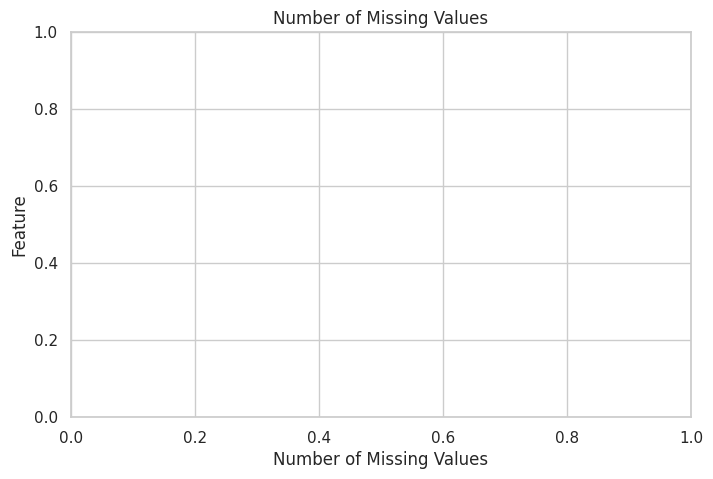

In [9]:
# ============================================
# 8. MISSING VALUE PLOT
# ============================================

missing_plot = (
    train_df.isnull()
    .sum()
    .sort_values(ascending=False)
)

missing_plot = missing_plot[
    missing_plot > 0
]

plt.figure(figsize=(8, 5))

sns.barplot(
    x=missing_plot.values,
    y=missing_plot.index
)

plt.title("Number of Missing Values")
plt.xlabel("Number of Missing Values")
plt.ylabel("Feature")

plt.show()

In [10]:
# ============================================
# 9. AIRLINE MISSINGNESS ANALYSIS
# ============================================

train_df["airline_missing"] = (
    train_df["airline"].isna()
)

display(
    train_df.groupby(
        "airline_missing"
    )["price"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .round(2)
)

,count,mean,median,std,min,max
airline_missing,,,,,,
False,18076,280.26,234.0,221.97,0,8996


In [11]:
# ============================================
# 10. DURATION MISSINGNESS ANALYSIS
# ============================================

train_df["duration_missing"] = (
    train_df["duration"].isna()
)

display(
    train_df.groupby(
        "duration_missing"
    )["price"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .round(2)
)

,count,mean,median,std,min,max
duration_missing,,,,,,
False,18076,280.26,234.0,221.97,0,8996


In [12]:
# ============================================
# 11. MISSING DURATION BY ROUTE
# ============================================

duration_missing_route = (
    train_df[
        train_df["duration"].isna()
    ]
    .groupby([
        "source_city",
        "destination_city"
    ])
    .size()
    .sort_values(ascending=False)
)

display(
    duration_missing_route.head(20)
)

Series([], dtype: int64)

In [13]:
# ============================================
# 12. MISSING DURATION BY STOPS
# ============================================

display(
    pd.crosstab(
        train_df["duration_missing"],
        train_df["stops"],
        normalize="index"
    ).round(3)
)

stops,one,two_or_more,zero
duration_missing,,,
False,0.239,0.011,0.75


In [14]:
# ============================================
# 13. MISSING AIRLINE BY FLIGHT CLASS
# ============================================

display(
    pd.crosstab(
        train_df["airline_missing"],
        train_df["flight_class"],
        normalize="index"
    ).round(3)
)

flight_class,Business,Economy
airline_missing,,
False,0.407,0.593


In [15]:
# ============================================
# 14. MISSING AIRLINE BY SOURCE CITY
# ============================================

display(
    pd.crosstab(
        train_df["airline_missing"],
        train_df["source_city"],
        normalize="index"
    ).round(3)
)

source_city,Los Angeles,Sacramento,San Diego,San Francisco,San Jose
airline_missing,,,,,
False,0.252,0.195,0.204,0.226,0.123


In [16]:
# ============================================
# 15. MISSING AIRLINE BY DESTINATION CITY
# ============================================

display(
    pd.crosstab(
        train_df["airline_missing"],
        train_df["destination_city"],
        normalize="index"
    ).round(3)
)

destination_city,Los Angeles,Sacramento,San Diego,San Francisco,San Jose
airline_missing,,,,,
False,0.251,0.183,0.207,0.225,0.134


In [17]:
# ============================================
# 16. DURATION BY ROUTE
# ============================================

route_duration = (
    train_df[
        train_df["duration"].notna()
    ]
    .groupby([
        "source_city",
        "destination_city"
    ])["duration"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
)

display(
    route_duration
    .sort_values("count", ascending=False)
    .head(20)
    .round(2)
)

,,count,mean,median,std,min,max
source_city,destination_city,,,,,,
San Francisco,Los Angeles,2065,1.60,1.60,0.50,1.32,12.60
Los Angeles,San Francisco,1995,1.47,1.43,0.26,1.25,10.22
San Francisco,San Diego,1305,1.80,1.73,0.74,1.50,18.50
San Diego,San Francisco,1257,1.79,1.77,0.79,1.50,20.55
Sacramento,Los Angeles,990,1.95,1.65,1.85,1.40,23.20
Los Angeles,Sacramento,977,1.87,1.53,2.27,1.33,28.63
Sacramento,San Jose,872,6.39,5.30,3.40,3.08,26.05
Los Angeles,San Diego,847,2.99,3.25,2.53,0.88,16.55
San Diego,Sacramento,847,3.29,1.80,4.50,1.58,28.65


In [18]:
# ============================================
# 16. DURATION BY ROUTE
# ============================================

route_duration = (
    train_df[
        train_df["duration"].notna()
    ]
    .groupby([
        "source_city",
        "destination_city"
    ])["duration"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
)

display(
    route_duration
    .sort_values("count", ascending=False)
    .head(20)
    .round(2)
)

,,count,mean,median,std,min,max
source_city,destination_city,,,,,,
San Francisco,Los Angeles,2065,1.60,1.60,0.50,1.32,12.60
Los Angeles,San Francisco,1995,1.47,1.43,0.26,1.25,10.22
San Francisco,San Diego,1305,1.80,1.73,0.74,1.50,18.50
San Diego,San Francisco,1257,1.79,1.77,0.79,1.50,20.55
Sacramento,Los Angeles,990,1.95,1.65,1.85,1.40,23.20
Los Angeles,Sacramento,977,1.87,1.53,2.27,1.33,28.63
Sacramento,San Jose,872,6.39,5.30,3.40,3.08,26.05
Los Angeles,San Diego,847,2.99,3.25,2.53,0.88,16.55
San Diego,Sacramento,847,3.29,1.80,4.50,1.58,28.65


In [19]:
train_df.drop(
    columns=[
        "airline_missing",
        "duration_missing"
    ],
    inplace=True
)

In [20]:
# ============================================
# 18. PRICE STATISTICS
# ============================================

display(
    train_df["price"].describe().to_frame()
)

,price
count,18076.000000
mean,280.264550
std,221.965133
min,0.000000
25%,157.000000
50%,234.000000
75%,336.000000
max,8996.000000


In [21]:
price_stats = pd.DataFrame({
    "Mean": [train_df["price"].mean()],
    "Median": [train_df["price"].median()],
    "Std": [train_df["price"].std()],
    "Minimum": [train_df["price"].min()],
    "Maximum": [train_df["price"].max()],
    "Skewness": [train_df["price"].skew()]
})

display(price_stats.round(2))

,Mean,Median,Std,Minimum,Maximum,Skewness
0,280.26,234.0,221.97,0,8996,7.07


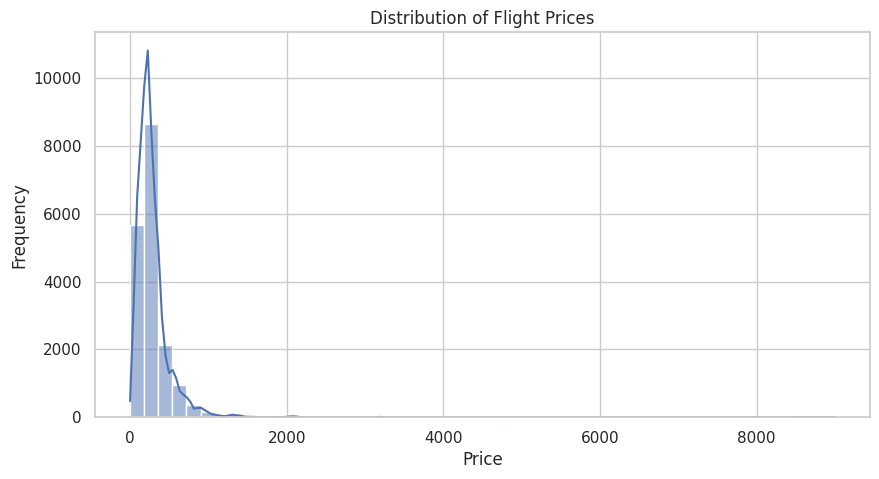

In [22]:
# ============================================
# 19. PRICE DISTRIBUTION
# ============================================

plt.figure(figsize=(10, 5))

sns.histplot(
    train_df["price"],
    bins=50,
    kde=True
)

plt.title("Distribution of Flight Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.show()

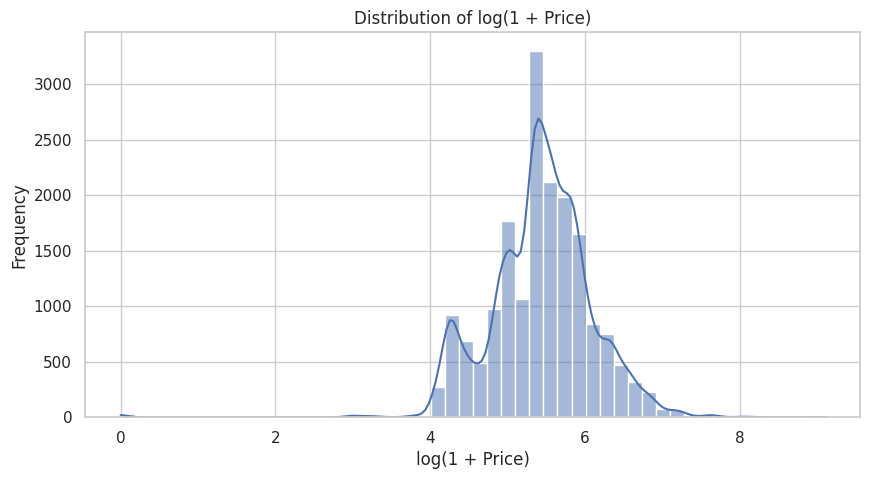

Original skewness: 7.07
Log-transformed skewness: -0.742


In [23]:
# ============================================
# 20. LOG PRICE DISTRIBUTION
# ============================================

log_price = np.log1p(
    train_df["price"]
)

plt.figure(figsize=(10, 5))

sns.histplot(
    log_price,
    bins=50,
    kde=True
)

plt.title("Distribution of log(1 + Price)")
plt.xlabel("log(1 + Price)")
plt.ylabel("Frequency")

plt.show()

print(
    "Original skewness:",
    round(train_df["price"].skew(), 3)
)

print(
    "Log-transformed skewness:",
    round(log_price.skew(), 3)
)

In [24]:
# ============================================
# 21. NUMERICAL FEATURES
# ============================================

numerical_features = [
    "duration",
    "days_left"
]

display(
    train_df[numerical_features]
    .describe()
    .T
)

,count,mean,std,min,25%,50%,75%,max
duration,18076.0,2.746853,2.947519,0.87,1.47,1.63,2.0,28.65
days_left,18076.0,20.520912,12.094984,1.00,10.00,20.00,31.0,44.00


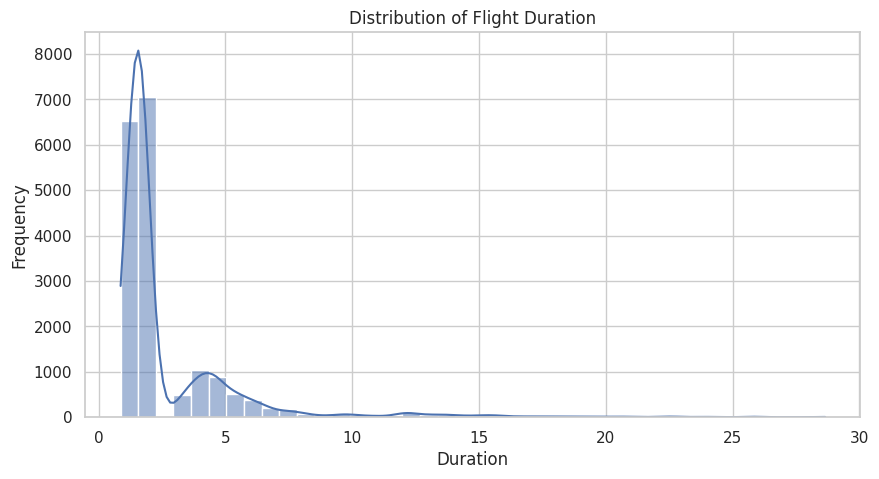

In [25]:
# ============================================
# 22. DURATION DISTRIBUTION
# ============================================

plt.figure(figsize=(10, 5))

sns.histplot(
    data=train_df,
    x="duration",
    bins=40,
    kde=True
)

plt.title("Distribution of Flight Duration")
plt.xlabel("Duration")
plt.ylabel("Frequency")

plt.show()

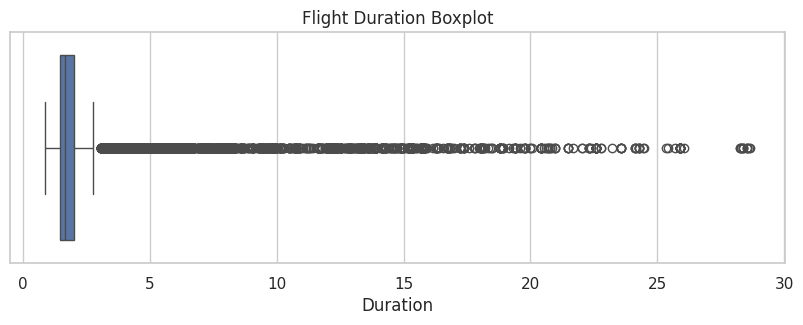

In [26]:
# ============================================
# 23. DURATION BOXPLOT
# ============================================

plt.figure(figsize=(10, 3))

sns.boxplot(
    x=train_df["duration"]
)

plt.title("Flight Duration Boxplot")
plt.xlabel("Duration")

plt.show()

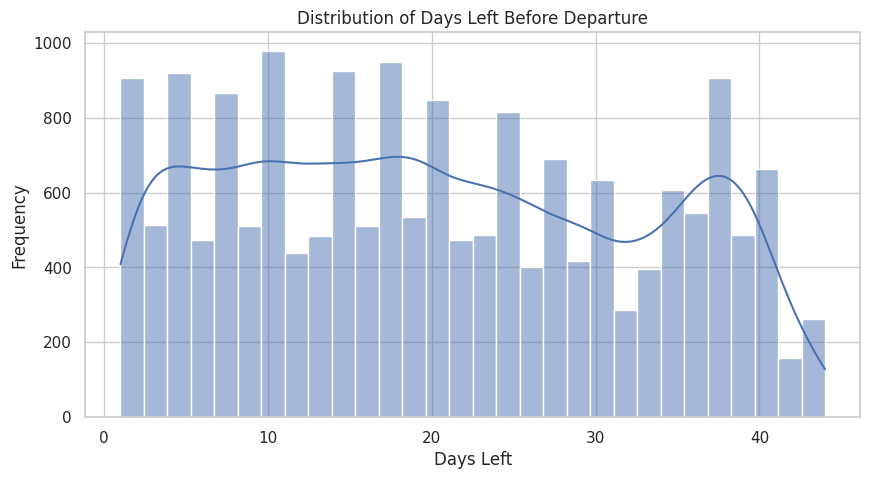

In [27]:
# ============================================
# 24. DAYS LEFT DISTRIBUTION
# ============================================

plt.figure(figsize=(10, 5))

sns.histplot(
    train_df["days_left"],
    bins=30,
    kde=True
)

plt.title("Distribution of Days Left Before Departure")
plt.xlabel("Days Left")
plt.ylabel("Frequency")

plt.show()

In [28]:
categorical_features = [
    "airline",
    "flight",
    "source_city",
    "departure_time",
    "stops",
    "arrival_time",
    "destination_city",
    "flight_class"
]

In [29]:
# ============================================
# 25. CATEGORICAL CARDINALITY
# ============================================

cardinality = pd.DataFrame({
    "Feature": categorical_features,
    "Unique Values": [
        train_df[col].nunique(dropna=False)
        for col in categorical_features
    ],
    "Missing Values": [
        train_df[col].isna().sum()
        for col in categorical_features
    ]
})

display(cardinality)

,Feature,Unique Values,Missing Values
0,airline,7,0
1,flight,1123,0
2,source_city,5,0
3,departure_time,6,0
4,stops,3,0
5,arrival_time,6,0
6,destination_city,5,0
7,flight_class,2,0


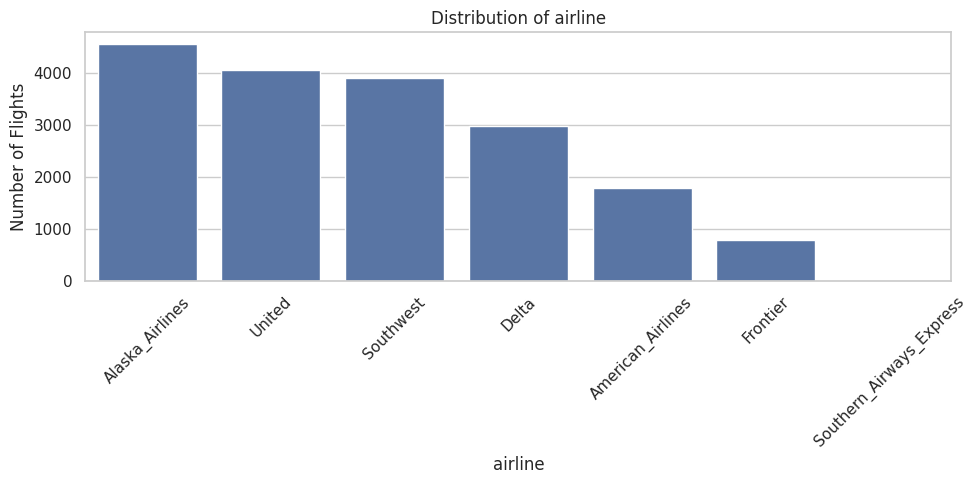

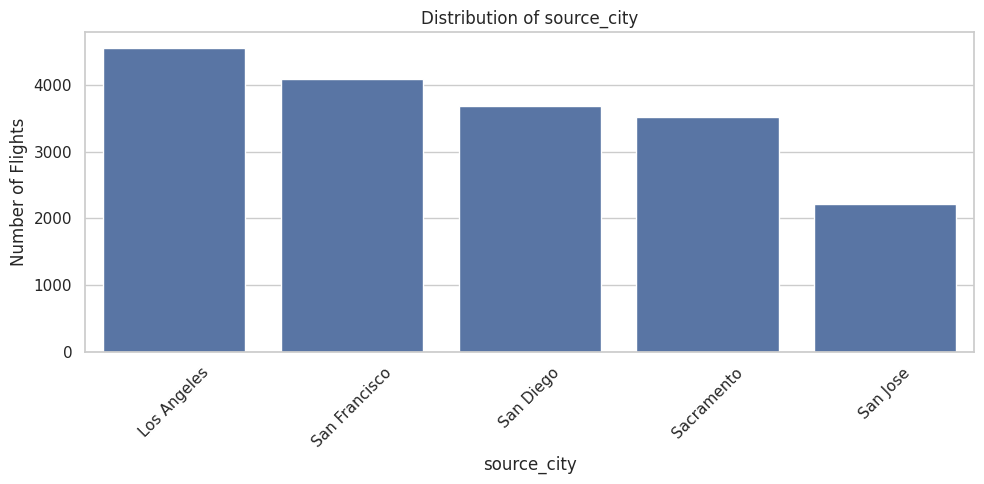

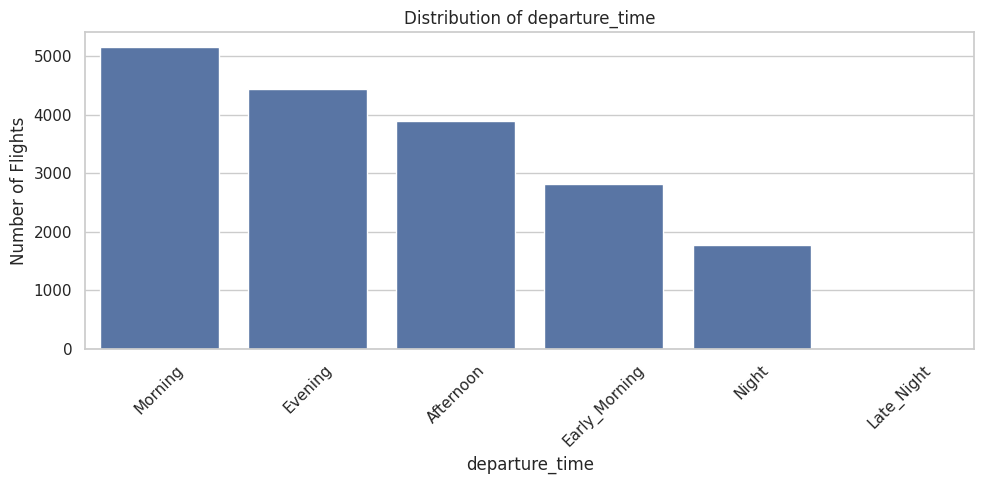

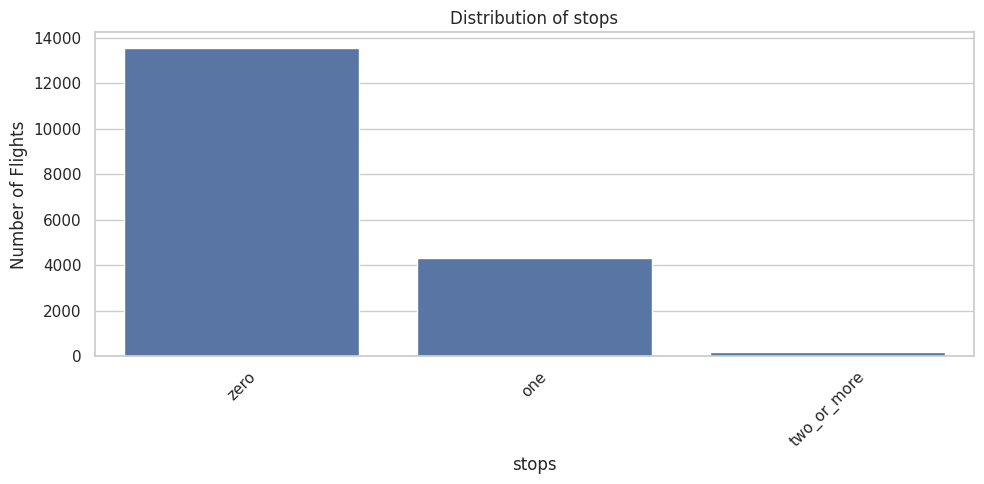

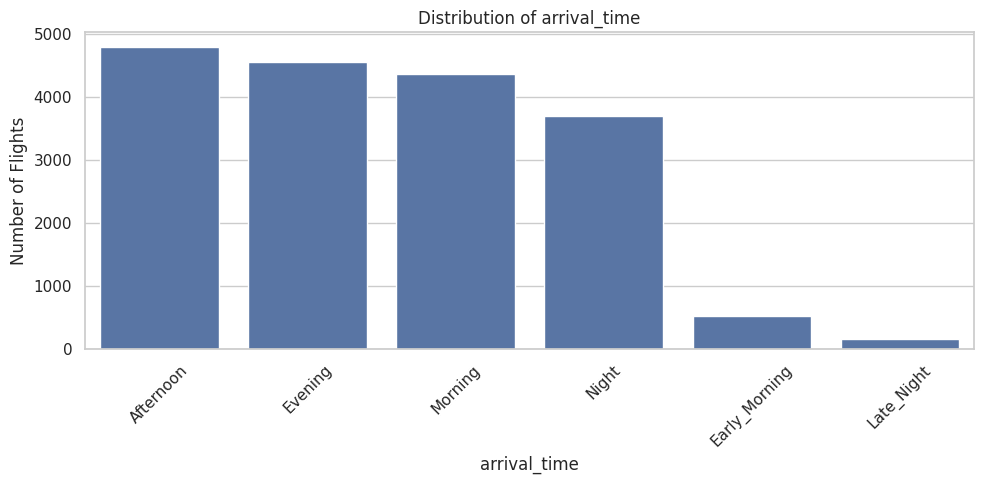

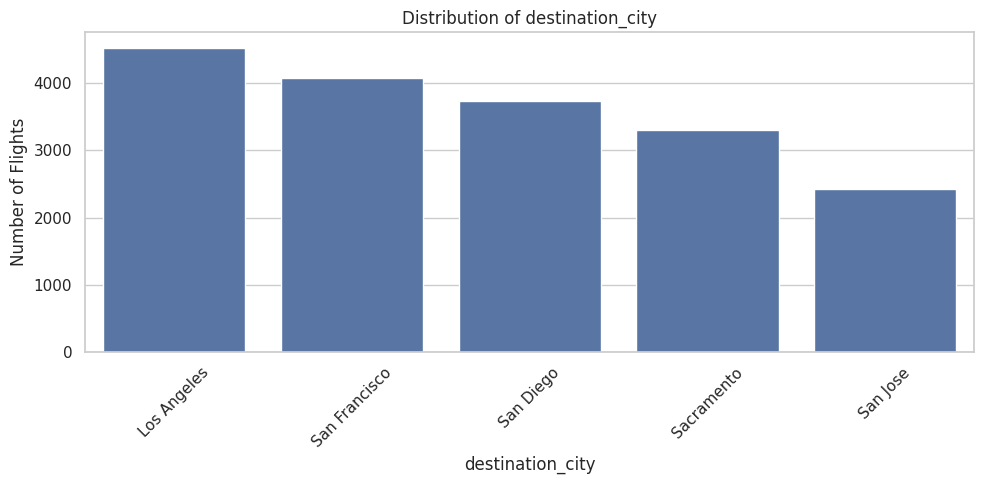

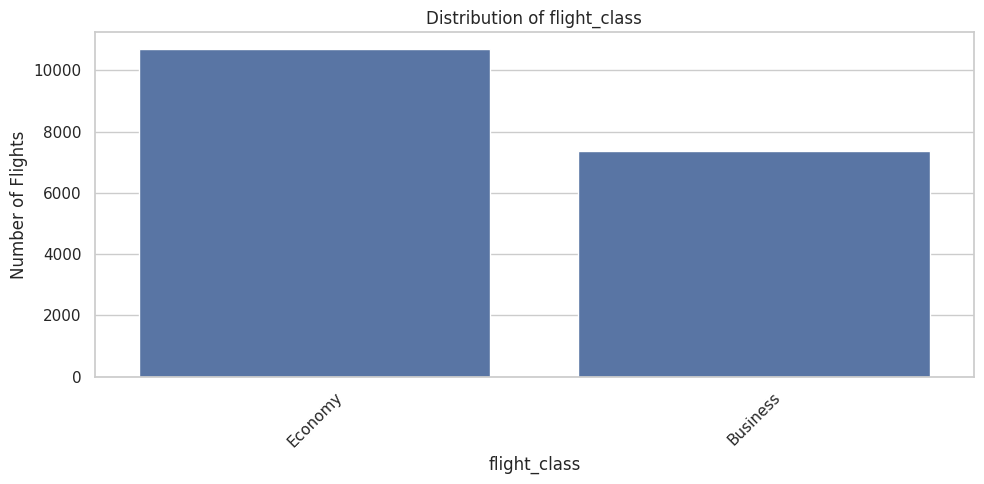

In [30]:
# ============================================
# 26. CATEGORICAL DISTRIBUTIONS
# ============================================

plot_features = [
    "airline",
    "source_city",
    "departure_time",
    "stops",
    "arrival_time",
    "destination_city",
    "flight_class"
]

for feature in plot_features:

    plt.figure(figsize=(10, 5))

    sns.countplot(
        data=train_df,
        x=feature,
        order=train_df[feature]
            .value_counts(dropna=False)
            .index
    )

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Number of Flights")

    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

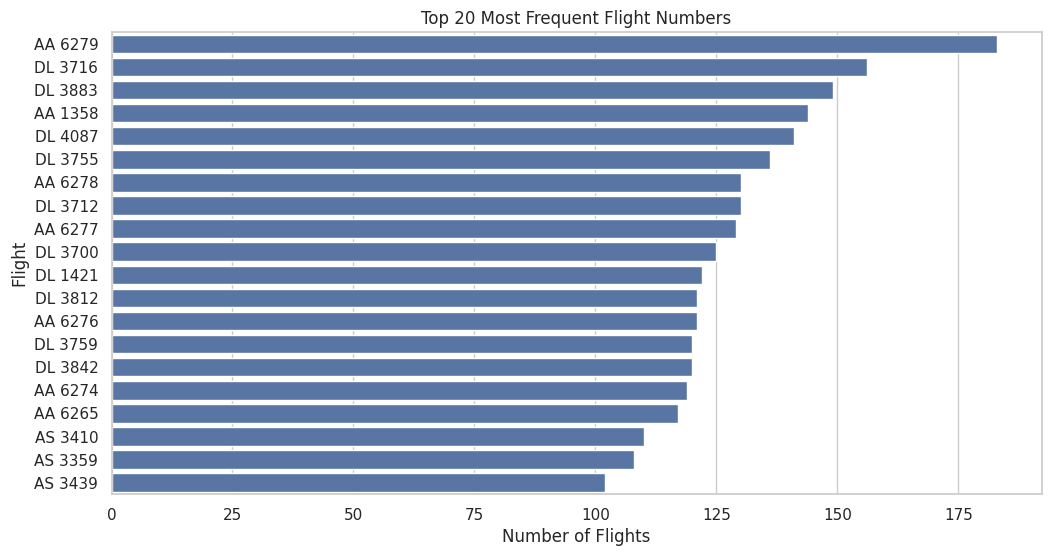

In [31]:
# ============================================
# 27. TOP 20 FLIGHTS
# ============================================

top_flights = (
    train_df["flight"]
    .value_counts()
    .head(20)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_flights.values,
    y=top_flights.index
)

plt.title("Top 20 Most Frequent Flight Numbers")
plt.xlabel("Number of Flights")
plt.ylabel("Flight")

plt.show()

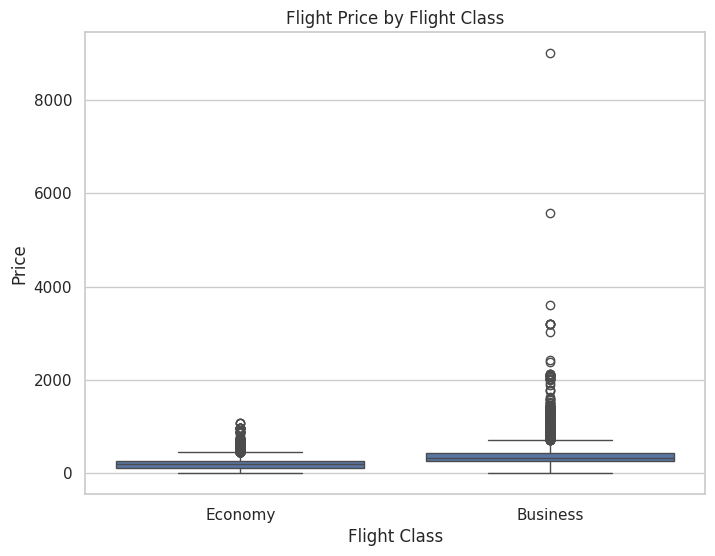

In [32]:
# ============================================
# 29. PRICE BY FLIGHT CLASS
# ============================================

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=train_df,
    x="flight_class",
    y="price"
)

plt.title("Flight Price by Flight Class")
plt.xlabel("Flight Class")
plt.ylabel("Price")

plt.show()

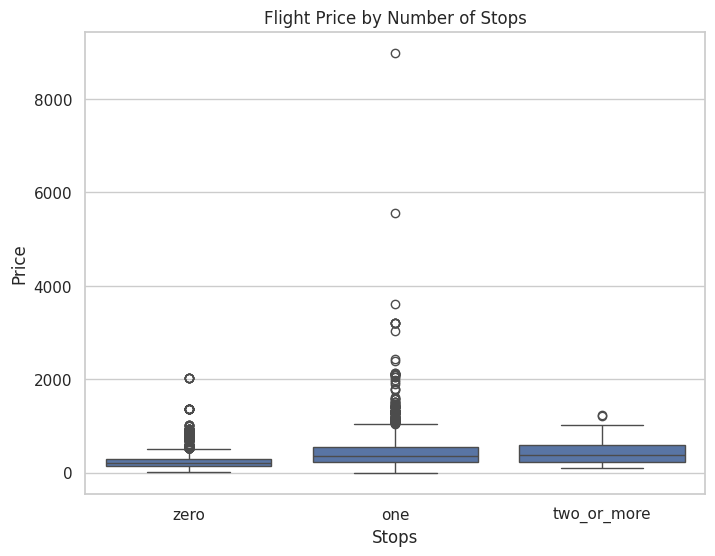

In [33]:
# ============================================
# 30. PRICE BY STOPS
# ============================================

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=train_df,
    x="stops",
    y="price"
)

plt.title("Flight Price by Number of Stops")
plt.xlabel("Stops")
plt.ylabel("Price")

plt.show()

In [34]:
# ============================================
# 31. ROUTE-LEVEL PRICE ANALYSIS
# ============================================

route_price = (
    train_df
    .groupby([
        "source_city",
        "destination_city"
    ])["price"]
    .agg([
        "count",
        "mean",
        "median",
        "std"
    ])
    .sort_values("median", ascending=False)
)

display(
    route_price.head(20).round(2)
)

count    mean  median     std
source_city   destination_city                               
Sacramento    San Jose            872  583.65   535.5  373.05
San Jose      Sacramento          763  538.16   470.0  332.64
San Francisco Sacramento          716  404.49   349.0  186.10
Sacramento    San Francisco       821  381.95   347.0  170.96
San Diego     Los Angeles         777  338.89   328.0  130.16
Los Angeles   San Diego           847  344.09   328.0  330.41
              San Jose            742  256.15   234.0  226.69
San Jose      Los Angeles         701  269.18   234.0  199.27
San Diego     Sacramento          847  216.35   224.0  106.99
Los Angeles   Sacramento          977  237.81   222.0  113.22
Sacramento    Los Angeles         990  237.08   222.0  109.03
              San Diego           838  223.61   212.0  131.77
Los Angeles   San Francisco      1995  232.78   207.0  154.89
San Francisco Los Angeles        2065  235.31   207.0  158.58
San Jose      San Diego           753  208.64   205.0  116.27
San Diego     San Jose            810  220.38   194.0  269.13
              San Francisco      1257  190.04   149.0  130.87
San Francisco San Diego          1305  189.50   149.0  132.90

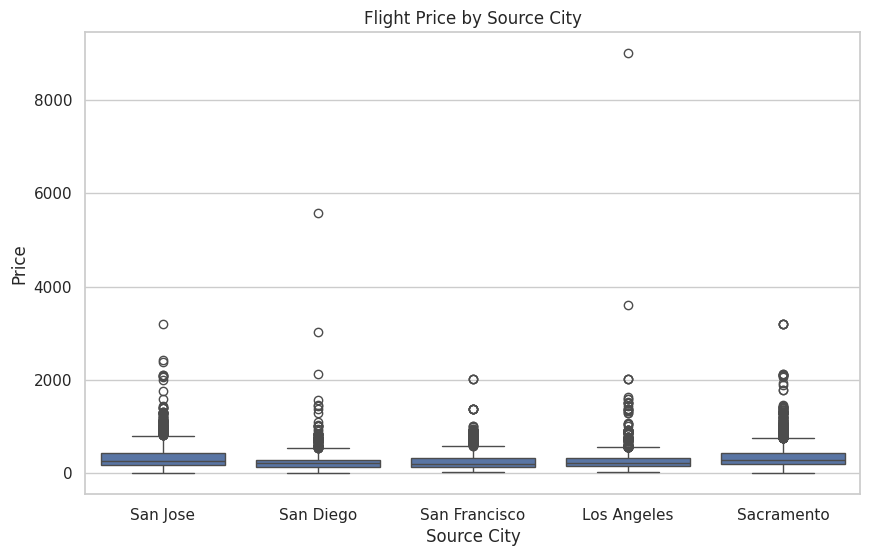

In [35]:
# ============================================
# 32. PRICE BY SOURCE CITY
# ============================================

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=train_df,
    x="source_city",
    y="price"
)

plt.title("Flight Price by Source City")
plt.xlabel("Source City")
plt.ylabel("Price")

plt.show()

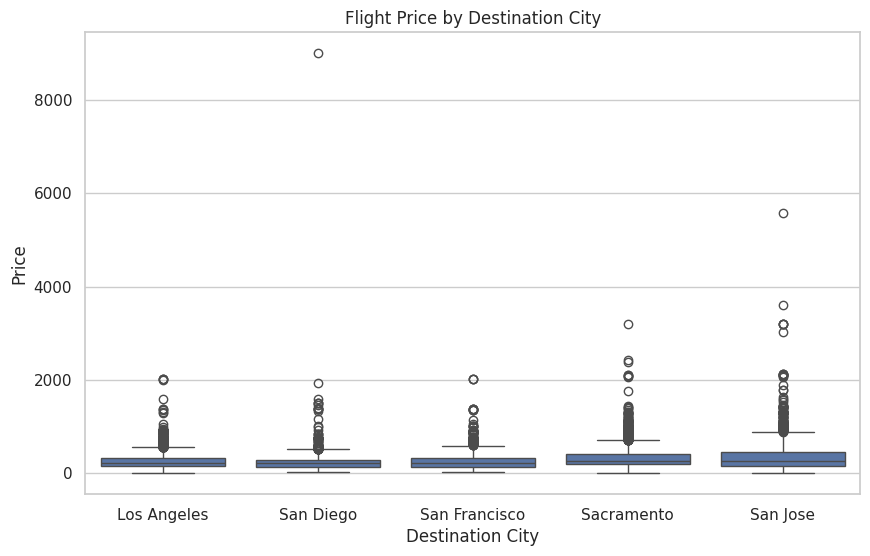

In [36]:
# ============================================
# 33. PRICE BY DESTINATION CITY
# ============================================

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=train_df,
    x="destination_city",
    y="price"
)

plt.title("Flight Price by Destination City")
plt.xlabel("Destination City")
plt.ylabel("Price")

plt.show()

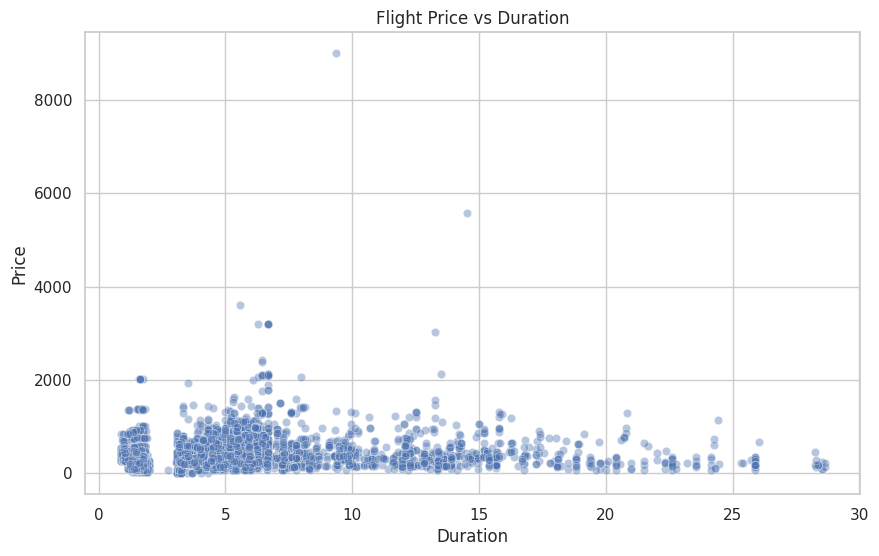

In [37]:
# ============================================
# 34. PRICE VS DURATION
# ============================================

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=train_df,
    x="duration",
    y="price",
    alpha=0.4
)

plt.title("Flight Price vs Duration")
plt.xlabel("Duration")
plt.ylabel("Price")

plt.show()

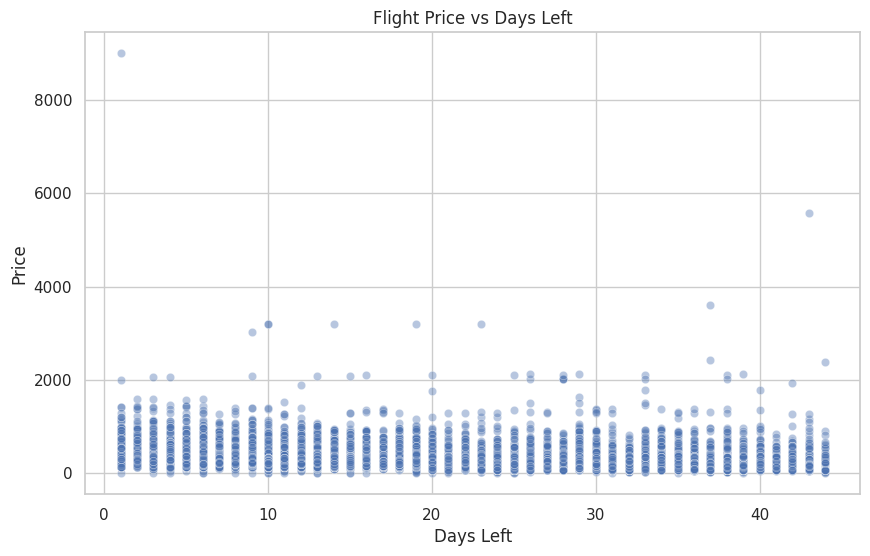

In [38]:
# ============================================
# 35. PRICE VS DAYS LEFT
# ============================================

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=train_df,
    x="days_left",
    y="price",
    alpha=0.4
)

plt.title("Flight Price vs Days Left")
plt.xlabel("Days Left")
plt.ylabel("Price")

plt.show()

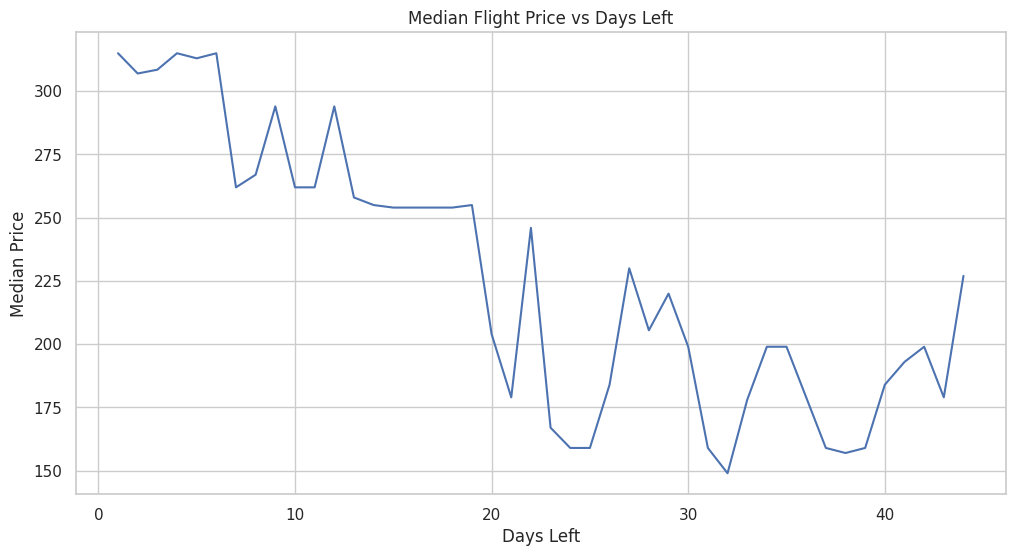

In [39]:
# ============================================
# 36. MEDIAN PRICE VS DAYS LEFT
# ============================================

days_price = (
    train_df
    .groupby("days_left")["price"]
    .median()
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=days_price,
    x="days_left",
    y="price"
)

plt.title("Median Flight Price vs Days Left")
plt.xlabel("Days Left")
plt.ylabel("Median Price")

plt.show()

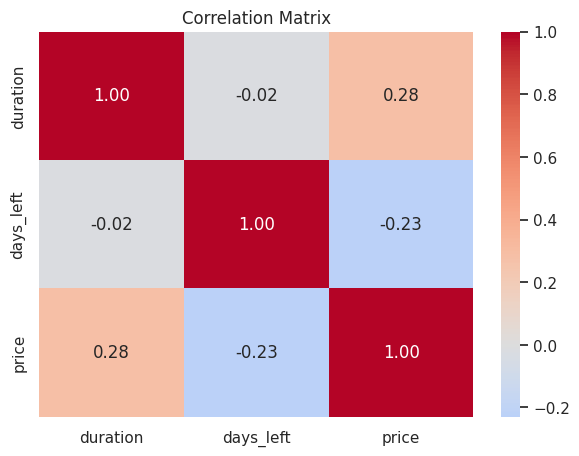

In [40]:
# ============================================
# 37. CORRELATION MATRIX
# ============================================

correlation_features = [
    "duration",
    "days_left",
    "price"
]

correlation_matrix = train_df[
    correlation_features
].corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix")
plt.show()

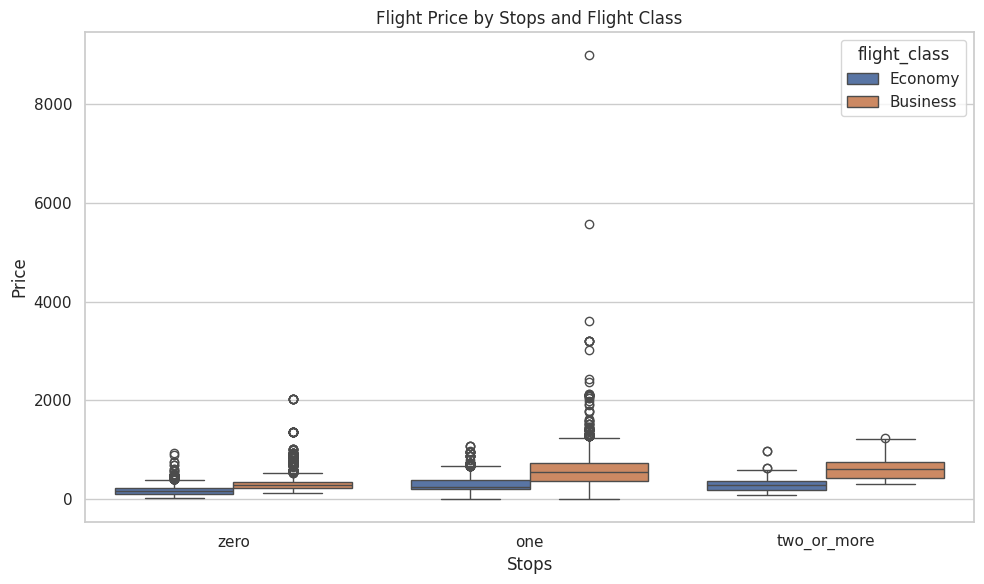

In [41]:
# ============================================
# 38. CLASS × STOPS × PRICE
# ============================================

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=train_df,
    x="stops",
    y="price",
    hue="flight_class"
)

plt.title("Flight Price by Stops and Flight Class")
plt.xlabel("Stops")
plt.ylabel("Price")

plt.tight_layout()
plt.show()

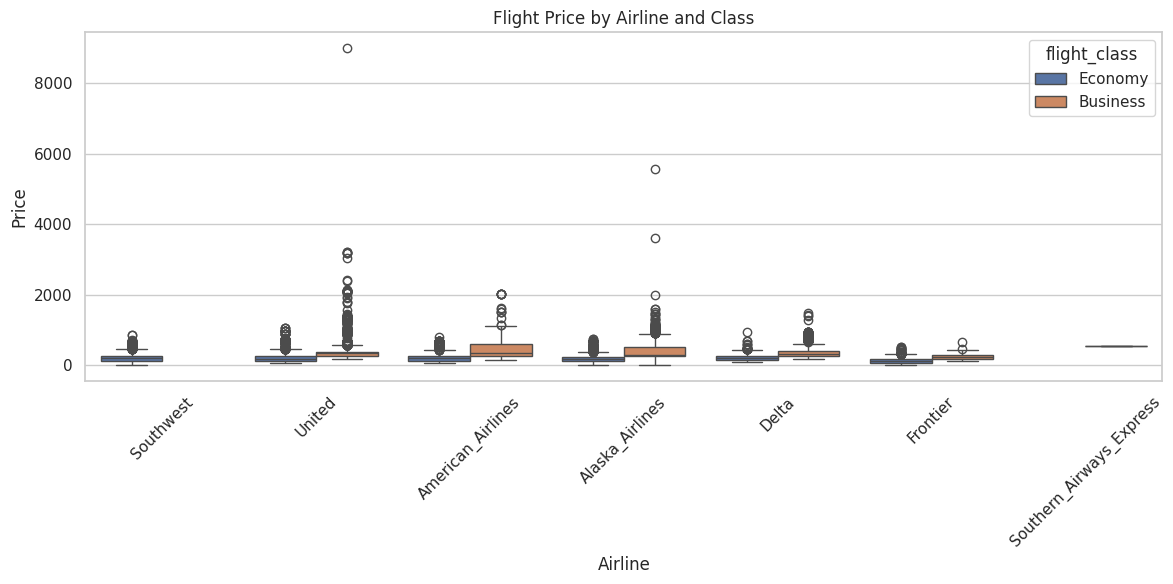

In [42]:
# ============================================
# 39. AIRLINE × CLASS
# ============================================

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=train_df,
    x="airline",
    y="price",
    hue="flight_class"
)

plt.title("Flight Price by Airline and Class")
plt.xlabel("Airline")
plt.ylabel("Price")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [43]:
# ============================================
# 40. PRICE OUTLIER ANALYSIS
# ============================================

Q1 = train_df["price"].quantile(0.25)
Q3 = train_df["price"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = train_df[
    (train_df["price"] < lower_bound) |
    (train_df["price"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

print("Potential outliers:", len(outliers))

print(
    "Percentage:",
    round(
        len(outliers) / len(train_df) * 100,
        2
    )
)

Q1: 157.0
Q3: 336.0
IQR: 179.0
Lower bound: -111.5
Upper bound: 604.5
Potential outliers: 1120
Percentage: 6.2


In [44]:
# ============================================
# 41. HIGH PRICE OBSERVATIONS
# ============================================

display(
    train_df
    .sort_values("price", ascending=False)
    .head(20)
)

,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
15787,16,United,UA 729,Los Angeles,Late_Night,one,Morning,San Diego,Business,9.37,1,8996
15200,22275,Alaska_Airlines,AS 2224,San Diego,Night,one,Afternoon,San Jose,Business,14.52,43,5564
5936,19925,Alaska_Airlines,AS 668,Los Angeles,Early_Morning,one,Afternoon,San Jose,Business,5.58,37,3607
12601,11469,United,UA 1055,Sacramento,Morning,one,Evening,San Jose,Business,6.70,19,3204
2473,13008,United,UA 1055,Sacramento,Morning,one,Evening,San Jose,Business,6.70,23,3204
12674,5650,United,UA 1023,Sacramento,Morning,one,Evening,San Jose,Business,6.70,10,3194
10611,5522,United,UA 2013,San Jose,Morning,one,Afternoon,Sacramento,Business,6.28,10,3194
4249,7975,United,UA 1055,Sacramento,Morning,one,Evening,San Jose,Business,6.70,14,3194
7528,4233,United,UA 1100,San Diego,Night,one,Morning,San Jose,Business,13.27,9,3029
12109,19085,United,UA 2013,San Jose,Morning,one,Afternoon,Sacramento,Business,6.43,37,2424


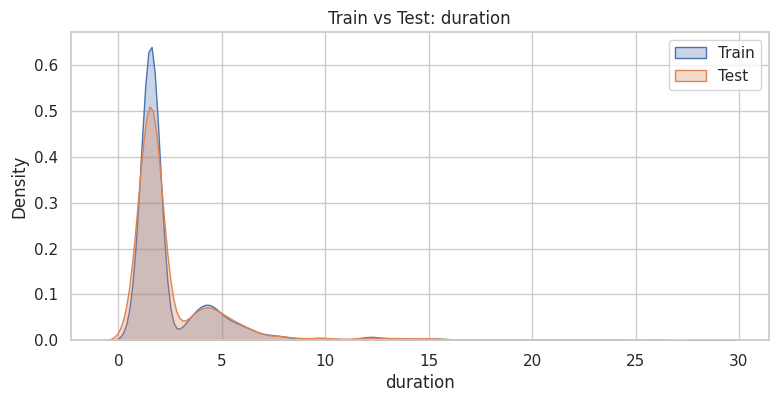

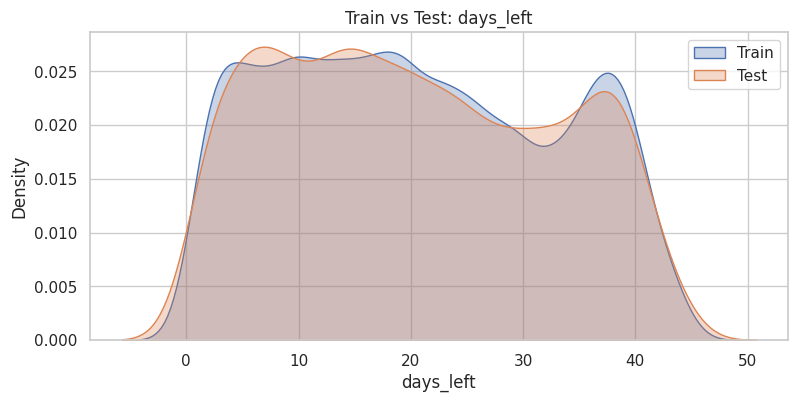

In [45]:
# ============================================
# 42. TRAIN VS TEST NUMERICAL FEATURES
# ============================================

for feature in numerical_features:

    plt.figure(figsize=(9, 4))

    sns.kdeplot(
        train_df[feature].dropna(),
        label="Train",
        fill=True,
        alpha=0.3
    )

    sns.kdeplot(
        test_df[feature].dropna(),
        label="Test",
        fill=True,
        alpha=0.3
    )

    plt.title(f"Train vs Test: {feature}")
    plt.xlabel(feature)
    plt.ylabel("Density")

    plt.legend()
    plt.show()

In [46]:
# ============================================
# 43. TRAIN VS TEST MISSINGNESS
# ============================================

train_missing = (
    train_df.isnull().mean() * 100
)

test_missing = (
    test_df.isnull().mean() * 100
)

missing_comparison = pd.DataFrame({
    "Train Missing %": train_missing,
    "Test Missing %": test_missing
})

display(
    missing_comparison.round(2)
)

,Train Missing %,Test Missing %
airline,0.0,0.0
arrival_time,0.0,0.0
days_left,0.0,0.0
departure_time,0.0,0.0
destination_city,0.0,0.0
duration,0.0,0.0
flight,0.0,0.0
flight_class,0.0,0.0
id,0.0,0.0
price,0.0,NaN


In [47]:
# ============================================
# 44. TRAIN VS TEST CATEGORICAL DISTRIBUTION
# ============================================

def compare_categorical_distribution(
    train,
    test,
    feature
):

    train_dist = (
        train[feature]
        .value_counts(
            normalize=True,
            dropna=False
        )
        .rename("Train")
    )

    test_dist = (
        test[feature]
        .value_counts(
            normalize=True,
            dropna=False
        )
        .rename("Test")
    )

    comparison = pd.concat(
        [train_dist, test_dist],
        axis=1
    ).fillna(0)

    comparison["Absolute Difference"] = (
        comparison["Test"] -
        comparison["Train"]
    ).abs()

    return comparison.sort_values(
        "Absolute Difference",
        ascending=False
    )


for feature in [
    "airline",
    "source_city",
    "destination_city",
    "flight_class",
    "stops"
]:

    print("\n" + "=" * 60)
    print(feature)
    print("=" * 60)

    display(
        compare_categorical_distribution(
            train_df,
            test_df,
            feature
        ).round(4)
    )


airline


,Train,Test,Absolute Difference
airline,,,
Southwest,0.2155,0.2029,0.0126
Delta,0.1644,0.1728,0.0084
American_Airlines,0.0994,0.1033,0.0039
United,0.2245,0.2250,0.0005
Frontier,0.0442,0.0440,0.0002
Southern_Airways_Express,0.0001,0.0000,0.0001
Alaska_Airlines,0.2519,0.2520,0.0001



source_city


,Train,Test,Absolute Difference
source_city,,,
Los Angeles,0.2523,0.2721,0.0198
Sacramento,0.1948,0.1803,0.0145
San Diego,0.2042,0.1945,0.0097
San Jose,0.1226,0.1268,0.0041
San Francisco,0.2260,0.2263,0.0003



destination_city


,Train,Test,Absolute Difference
destination_city,,,
San Jose,0.1341,0.1310,0.0031
San Diego,0.2071,0.2093,0.0022
Sacramento,0.1827,0.1841,0.0013
San Francisco,0.2253,0.2246,0.0008
Los Angeles,0.2508,0.2511,0.0003



flight_class


,Train,Test,Absolute Difference
flight_class,,,
Business,0.4074,0.4064,0.001
Economy,0.5926,0.5936,0.001



stops


,Train,Test,Absolute Difference
stops,,,
zero,0.7501,0.7467,0.0034
one,0.2392,0.2416,0.0024
two_or_more,0.0107,0.0117,0.0010


In [48]:
# ============================================
# 45. SUBMISSION FORMAT
# ============================================

print("Sample submission columns:")
print(sample_submission.columns.tolist())

print("\nShape:")
print(sample_submission.shape)

display(sample_submission.head())

Sample submission columns:
['id', 'price']

Shape:
(4520, 2)


,id,price
0,18395,18395
1,11771,11771
2,22326,22326
3,18332,18332
4,11021,11021


In [49]:

# ============================================
# 46. MODELING SETUP
# ============================================

from sklearn.model_selection import train_test_split, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

TARGET = "price"

base_cats = [
    "airline", "flight", "source_city", "departure_time",
    "stops", "arrival_time", "destination_city", "flight_class"
]

base_nums = ["duration", "days_left"]

print("Missing values:")
display(train_df.isnull().sum().to_frame("Missing Count"))

Missing values:


,Missing Count
id,0
airline,0
flight,0
source_city,0
departure_time,0
stops,0
arrival_time,0
destination_city,0
flight_class,0
duration,0


In [50]:

# ============================================
# 47. LEAKAGE-SAFE IMPUTATION
# ============================================

def feature_engineer_fit(X):
    """
    Learn all imputation mappings from the training data only.
    """
    X = X.copy()

    # 1) Recover airline from the flight prefix.
    # Example: AI 2943 -> AI -> airline mapping learned from observed rows.
    observed = X.dropna(subset=["airline"]).copy()
    observed["flight_code"] = observed["flight"].str.split().str[0]

    airline_mapping = (
        observed.groupby("flight_code")["airline"]
        .agg(lambda s: s.mode().iloc[0])
        .to_dict()
    )

    flight_code = X["flight"].str.split().str[0]
    missing_airline = X["airline"].isna()

    X.loc[missing_airline, "airline"] = (
        flight_code[missing_airline].map(airline_mapping)
    )

    fallback_airline = (
        observed["airline"].mode().iloc[0]
        if len(observed) else "Unknown"
    )

    X["airline"] = X["airline"].fillna(fallback_airline)

    # 2) Duration: flight-specific median first.
    flight_duration_median = X.groupby("flight")["duration"].median()

    X["duration"] = X["duration"].fillna(
        X["flight"].map(flight_duration_median)
    )

    # 3) Global median fallback.
    global_duration_median = X["duration"].median()
    X["duration"] = X["duration"].fillna(global_duration_median)

    return X, airline_mapping, flight_duration_median, global_duration_median


def feature_engineer_apply(
    X, airline_mapping, flight_duration_median, global_duration_median
):
    """
    Apply mappings learned from the training data.
    """
    X = X.copy()

    flight_code = X["flight"].str.split().str[0]
    missing_airline = X["airline"].isna()

    X.loc[missing_airline, "airline"] = (
        flight_code[missing_airline].map(airline_mapping)
    )

    fallback_airline = (
        next(iter(airline_mapping.values()))
        if airline_mapping else "Unknown"
    )

    X["airline"] = X["airline"].fillna(fallback_airline)

    X["duration"] = X["duration"].fillna(
        X["flight"].map(flight_duration_median)
    )
    X["duration"] = X["duration"].fillna(global_duration_median)

    return X

In [51]:

# ============================================
# 48. FEATURE ENGINEERING
# ============================================

def add_model_features(X):
    X = X.copy()

    # Categorical interaction features
    X["route"] = (
        X["source_city"].astype(str) + "__" +
        X["destination_city"].astype(str)
    )

    X["airline_class"] = (
        X["airline"].astype(str) + "__" +
        X["flight_class"].astype(str)
    )

    X["route_class"] = (
        X["route"].astype(str) + "__" +
        X["flight_class"].astype(str)
    )

    X["stops_class"] = (
        X["stops"].astype(str) + "__" +
        X["flight_class"].astype(str)
    )

    # Flight number can have different pricing for different classes/stops.
    X["flight_class_flight"] = (
        X["flight"].astype(str) + "__" +
        X["flight_class"].astype(str)
    )

    X["flight_stops"] = (
        X["flight"].astype(str) + "__" +
        X["stops"].astype(str)
    )

    X["flight_route"] = (
        X["flight"].astype(str) + "__" +
        X["route"].astype(str)
    )

    # Numeric nonlinear terms. The final model is still linear in coefficients.
    X["duration_sq"] = X["duration"] ** 2
    X["days_left_sq"] = X["days_left"] ** 2
    X["duration_days"] = X["duration"] * X["days_left"]
    X["log_duration"] = np.log1p(X["duration"])
    X["log_days_left"] = np.log1p(X["days_left"])

    # Allow slopes to differ by flight class / stops.
    business = (X["flight_class"] == "Business").astype(int)
    one_stop = (X["stops"] == "one").astype(int)
    multi_stop = (X["stops"] == "two_or_more").astype(int)

    X["duration_business"] = X["duration"] * business
    X["days_business"] = X["days_left"] * business
    X["duration_one_stop"] = X["duration"] * one_stop
    X["duration_multi_stop"] = X["duration"] * multi_stop
    X["days_business_sq"] = (X["days_left"] ** 2) * business

    return X


model_cats = base_cats + [
    "route",
    "airline_class",
    "route_class",
    "stops_class",
    "flight_class_flight",
    "flight_stops",
    "flight_route"
]

model_nums = base_nums + [
    "duration_sq",
    "days_left_sq",
    "duration_days",
    "log_duration",
    "log_days_left",
    "duration_business",
    "days_business",
    "duration_one_stop",
    "duration_multi_stop",
    "days_business_sq"
]

print("Categorical model features:", len(model_cats))
print("Numerical model features:", len(model_nums))


Categorical model features: 15
Numerical model features: 12


In [52]:

# ============================================
# 49. PREPROCESSOR + MODEL
# ============================================

def make_preprocessor(use_scaling=True):
    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if use_scaling:
        numeric_steps.append(("scaler", StandardScaler()))

    return ColumnTransformer([
        (
            "num",
            Pipeline(numeric_steps),
            model_nums
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                (
                    "onehot",
                    OneHotEncoder(handle_unknown="ignore")
                )
            ]),
            model_cats
        )
    ])


def build_model(alpha=None):
    if alpha is None:
        estimator = LinearRegression()
        use_scaling = False
    else:
        estimator = Ridge(alpha=alpha)
        use_scaling = True

    return Pipeline([
        ("preprocessor", make_preprocessor(use_scaling)),
        ("model", estimator)
    ])

In [53]:

# ============================================
# 50. TRAIN / VALIDATION SPLIT
# ============================================

train_part, val_part = train_test_split(
    train_df,
    test_size=0.20,
    random_state=42
)

train_part = train_part.reset_index(drop=True)
val_part = val_part.reset_index(drop=True)

print("Model-training portion:", train_part.shape)
print("Validation portion:", val_part.shape)


def prepare_train_validation(train_data, val_data):
    X_train = train_data.drop(columns=TARGET)
    X_val = val_data.drop(columns=TARGET)

    X_train, airline_map, duration_map, global_duration = (
        feature_engineer_fit(X_train)
    )

    X_val = feature_engineer_apply(
        X_val,
        airline_map,
        duration_map,
        global_duration
    )

    X_train = add_model_features(X_train)
    X_val = add_model_features(X_val)

    y_train = train_data[TARGET].values
    y_val = val_data[TARGET].values

    return X_train, X_val, y_train, y_val


X_train, X_val, y_train, y_val = prepare_train_validation(
    train_part,
    val_part
)

Model-training portion: (14460, 12)
Validation portion: (3616, 12)


In [54]:

# ============================================
# 51. 5-FOLD CV FOR RIDGE ALPHA
# ============================================

def cv_rmse_for_alpha(data, alpha, n_splits=5):
    kfold = KFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=42
    )

    fold_rmse = []

    for fold, (tr_idx, cv_idx) in enumerate(
        kfold.split(data), start=1
    ):
        fold_train = data.iloc[tr_idx].reset_index(drop=True)
        fold_val = data.iloc[cv_idx].reset_index(drop=True)

        X_tr, X_cv, y_tr, y_cv = prepare_train_validation(
            fold_train,
            fold_val
        )

        model = build_model(alpha=alpha)
        model.fit(X_tr, y_tr)

        pred = model.predict(X_cv)

        fold_rmse.append(
            mean_squared_error(y_cv, pred) ** 0.5
        )

    return np.mean(fold_rmse)


alphas = [
    0.5, 1.0, 1.5, 2.0, 2.25, 2.5,
    2.75, 3.0, 3.25, 3.5, 4.0, 5.0
]

alpha_results = []

for alpha in alphas:
    rmse = cv_rmse_for_alpha(
        train_part,
        alpha=alpha,
        n_splits=5
    )

    alpha_results.append({
        "alpha": alpha,
        "CV_RMSE": rmse
    })

alpha_results = pd.DataFrame(alpha_results)
display(alpha_results.sort_values("CV_RMSE"))

best_alpha = (
    alpha_results
    .sort_values("CV_RMSE")
    .iloc[0]["alpha"]
)

print("Selected Ridge alpha:", best_alpha)

,alpha,CV_RMSE
11,5.00,123.983477
10,4.00,124.646995
9,3.50,125.110470
8,3.25,125.381486
7,3.00,125.687590
6,2.75,126.030404
5,2.50,126.413772
4,2.25,126.845182
3,2.00,127.323981
2,1.50,128.476351


Selected Ridge alpha: 5.0


In [55]:

# ============================================
# 52. FINAL VALIDATION CHECK
# ============================================
best_alpha=2.25
validation_model = build_model(alpha=best_alpha)

validation_model.fit(
    X_train,
    y_train
)

validation_pred = validation_model.predict(X_val)

validation_rmse = mean_squared_error(
    y_val,
    validation_pred
) ** 0.5

validation_mae = mean_absolute_error(
    y_val,
    validation_pred
)

validation_r2 = r2_score(
    y_val,
    validation_pred
)

print(f"Validation RMSE: {validation_rmse:,.2f}")
print(f"Validation MAE : {validation_mae:,.2f}")
print(f"Validation R²  : {validation_r2:.4f}")

Validation RMSE: 147.61
Validation MAE : 58.91
Validation R²  : 0.6127


In [56]:

# ============================================
# 52. FINAL VALIDATION CHECK
# ============================================

validation_model = build_model(alpha=best_alpha)

validation_model.fit(
    X_train,
    y_train
)

validation_pred = validation_model.predict(X_val)

validation_rmse = mean_squared_error(
    y_val,
    validation_pred
) ** 0.5

validation_mae = mean_absolute_error(
    y_val,
    validation_pred
)

validation_r2 = r2_score(
    y_val,
    validation_pred
)

print(f"Validation RMSE: {validation_rmse:,.2f}")
print(f"Validation MAE : {validation_mae:,.2f}")
print(f"Validation R²  : {validation_r2:.4f}")

Validation RMSE: 147.61
Validation MAE : 58.91
Validation R²  : 0.6127


In [57]:

# ============================================
# 53. LINEAR REGRESSION VS RIDGE
# ============================================

linear_model = build_model(alpha=None)

linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_val)

linear_rmse = mean_squared_error(
    y_val,
    linear_pred
) ** 0.5

print(f"Linear Regression validation RMSE: {linear_rmse:,.2f}")
print(f"Ridge Regression validation RMSE : {validation_rmse:,.2f}")

if validation_rmse < linear_rmse:
    print("Ridge is better -> use Ridge for the final submission.")
else:
    print("Plain Linear Regression is better -> use Linear Regression.")

Linear Regression validation RMSE: 146.63
Ridge Regression validation RMSE : 147.61
Plain Linear Regression is better -> use Linear Regression.


In [58]:

# ============================================
# 54. FINAL TRAINING ON ALL TRAINING DATA
# ============================================

X_full = train_df.drop(columns=TARGET)
X_test = test_df.copy()

X_full, final_airline_map, final_duration_map, final_global_duration = (
    feature_engineer_fit(X_full)
)

X_test = feature_engineer_apply(
    X_test,
    final_airline_map,
    final_duration_map,
    final_global_duration
)

X_full = add_model_features(X_full)
X_test = add_model_features(X_test)

final_model = build_model(alpha=best_alpha)

final_model.fit(
    X_full,
    train_df[TARGET].values
)

test_predictions = final_model.predict(X_test)

# Flight prices cannot be negative.
test_predictions = np.clip(
    test_predictions,
    a_min=0,
    a_max=None
)

print("Test predictions generated:", len(test_predictions))
print(pd.Series(test_predictions).describe())

Test predictions generated: 4520
count    4520.000000
mean      281.264009
std       185.143113
min         0.000000
25%       160.648569
50%       248.191394
75%       354.275594
max      1963.199659
dtype: float64


In [59]:

# ============================================
# 55. CREATE SAMPLE.CSV
# ============================================

submission = sample_submission.copy()

submission["price"] = test_predictions

# Ensure exact submission column order.
submission = submission[["id", "price"]]

submission.to_csv(
    "sample.csv",
    index=False
)

print("Saved: sample.csv")
print("Shape:", submission.shape)
display(submission.head())

Saved: sample.csv
Shape: (4520, 2)


,id,price
0,18395,53.447346
1,11771,148.483051
2,22326,407.396162
3,18332,135.026360
4,11021,430.476304
